# Notebook 02 — Khai phá dữ liệu bằng K-means

Notebook chạy lại toàn bộ thử nghiệm K-means thông qua `src/run_kmeans.py`, tạo lại bảng so sánh 21 cấu hình, kết quả phân nhóm, đánh giá độ ổn định và kiểm tra độ nhạy.

In [1]:
from pathlib import Path
import subprocess, sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "src" / "run_kmeans.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "src" / "run_kmeans.py").exists(), "Hãy mở notebook từ thư mục notebooks hoặc thư mục gốc dự án."
subprocess.run([sys.executable, str(ROOT / "src" / "run_kmeans.py")], check=True, cwd=ROOT)
DATA = ROOT / "data"


{
  "n_countries": 193,
  "k": 2,
  "selected_preprocessing": "RobustScaler - raw",
  "silhouette": 0.66376070176147,
  "calinski_harabasz": 249.62922081688765,
  "davies_bouldin": 0.635971663912603,
  "mean_pairwise_ari_10_seeds": 0.9847693940591371,
  "cluster_sizes": {
    "1": 167,
    "2": 26
  },
  "vietnam_cluster_id": 1
}
Model comparison: /mnt/data/TB-Insights-final-audit/TB-Insights-Streamlit-v1.2/data/TB_kmeans_model_comparison.csv
Validation: PASS


## 1. Tập dữ liệu và biến đầu vào

In [2]:
candidate = pd.read_csv(DATA / "TB_kmeans_candidate_2024.csv")
features = ["e_inc_100k", "e_mort_100k", "c_cdr"]
print("Complete cases:", len(candidate), "Unique ISO3:", candidate.iso3.nunique())
print("Missing values:", int(candidate[features].isna().sum().sum()))
print("c_cdr > 100:", int((candidate.c_cdr > 100).sum()))
display(candidate[["country", "iso3", "g_whoregion", *features]].head())
display(candidate[features].describe().T)


Complete cases: 193 Unique ISO3: 193
Missing values: 0
c_cdr > 100: 3


,country,iso3,g_whoregion,e_inc_100k,e_mort_100k,c_cdr
0,Afghanistan,AFG,EMR,203.0,34.00,59.0
1,Albania,ALB,EUR,15.0,0.32,57.0
2,Algeria,DZA,AFR,54.0,7.10,74.0
3,Andorra,AND,EUR,4.9,0.47,100.0
4,Angola,AGO,AFR,373.0,75.00,61.0


,count,mean,std,min,25%,50%,75%,max
e_inc_100k,193.0,104.350674,146.495435,0.29,10.00,46.0,138.0,945.0
e_mort_100k,193.0,15.614093,26.484389,0.01,0.57,4.1,19.0,187.0
c_cdr,193.0,75.953368,15.625930,18.00,67.00,74.0,86.0,140.0


## 2. So sánh 3 cách chuẩn hóa và K từ 2 đến 8

,preprocessing,preprocessing_vi,k,silhouette,calinski_harabasz,davies_bouldin,cluster_sizes_ascending,is_selected
14,RobustScaler - raw,RobustScaler · Dữ liệu gốc,2,0.663761,249.629221,0.635972,26;167,True
0,StandardScaler - raw,StandardScaler · Dữ liệu gốc,2,0.561811,176.225170,0.813259,35;158,False
15,RobustScaler - raw,RobustScaler · Dữ liệu gốc,3,0.478026,216.802352,0.838251,17;46;130,False
7,StandardScaler - log1p rates,StandardScaler · Log1p hai tỷ suất,2,0.469538,255.027784,0.777553,96;97,False
16,RobustScaler - raw,RobustScaler · Dữ liệu gốc,4,0.447929,206.272129,0.810021,3;19;51;120,False
18,RobustScaler - raw,RobustScaler · Dữ liệu gốc,6,0.444355,236.891714,0.775142,3;3;16;33;61;77,False
17,RobustScaler - raw,RobustScaler · Dữ liệu gốc,5,0.435895,228.558878,0.764930,3;18;34;61;77,False
1,StandardScaler - raw,StandardScaler · Dữ liệu gốc,3,0.431734,187.468139,0.773050,23;66;104,False
4,StandardScaler - raw,StandardScaler · Dữ liệu gốc,6,0.428446,164.380557,0.936890,3;4;16;31;63;76,False
2,StandardScaler - raw,StandardScaler · Dữ liệu gốc,4,0.428436,176.350014,0.882155,16;31;63;83,False


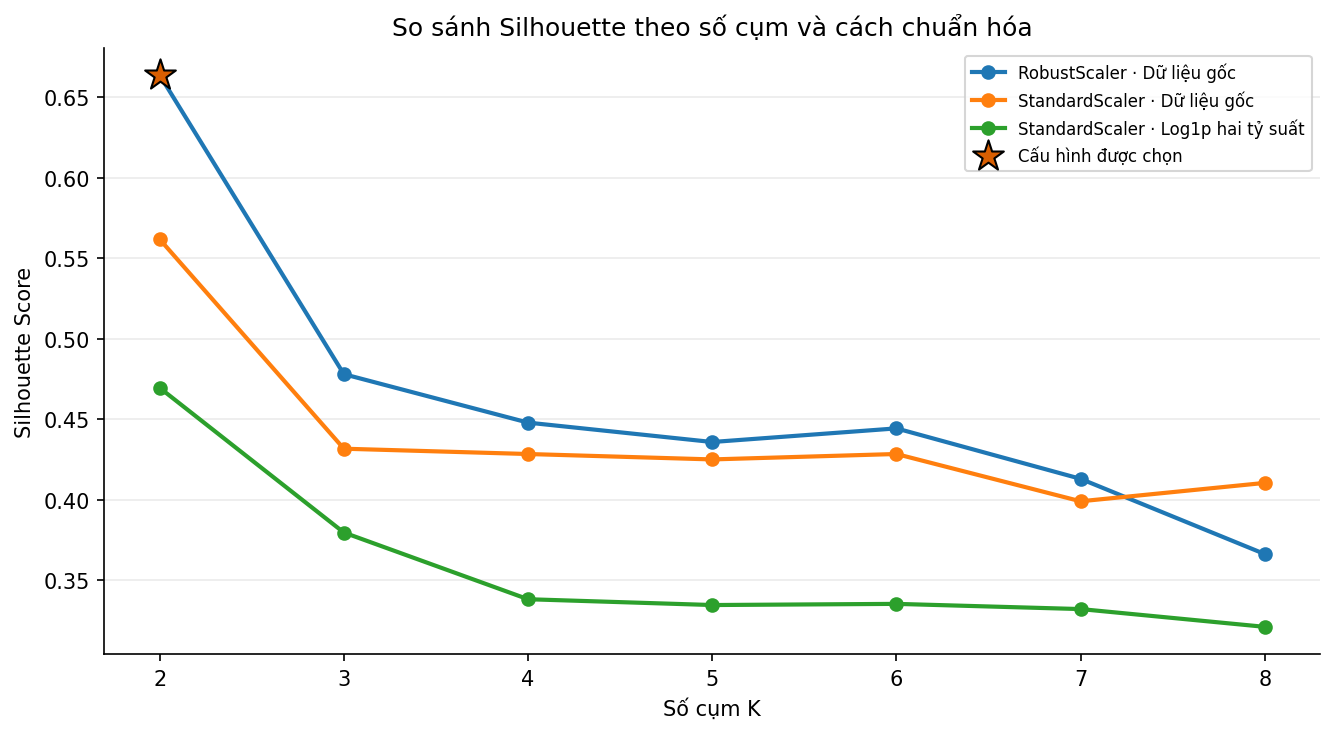

In [3]:
benchmark = pd.read_csv(DATA / "TB_kmeans_model_comparison.csv")
display(benchmark.sort_values("silhouette", ascending=False))
display(Image(filename=str(ROOT / "reports" / "figures" / "09_kmeans_silhouette_comparison.png")))


## 3. Kết quả mô hình được chọn

{
  "n_countries": 193,
  "k": 2,
  "selected_preprocessing": "RobustScaler - raw",
  "silhouette": 0.66376070176147,
  "calinski_harabasz": 249.62922081688765,
  "davies_bouldin": 0.635971663912603,
  "mean_pairwise_ari_10_seeds": 0.9847693940591371,
  "cluster_sizes": {
    "1": 167,
    "2": 26
  },
  "vietnam_cluster_id": 1
}


,cluster_id,cluster_name_vi,countries,incidence_median,incidence_mean,mortality_median,mortality_mean,cdr_median,cdr_mean,share_pct
0,1,Nhóm có hồ sơ gánh nặng tương đối thấp hơn,167,35.0,56.620838,2.6,7.278563,77.0,78.023952,86.528497
1,2,Nhóm có hồ sơ gánh nặng tương đối cao hơn,26,379.5,410.923077,64.0,69.153846,67.0,62.653846,13.471503


,country,iso3,g_whoregion,e_pop_num,e_inc_100k,e_mort_100k,c_cdr,cluster_id,cluster_name_vi
189,Viet Nam,VNM,WPR,100987689,182.0,12.0,58.0,1,Nhóm có hồ sơ gánh nặng tương đối thấp hơn


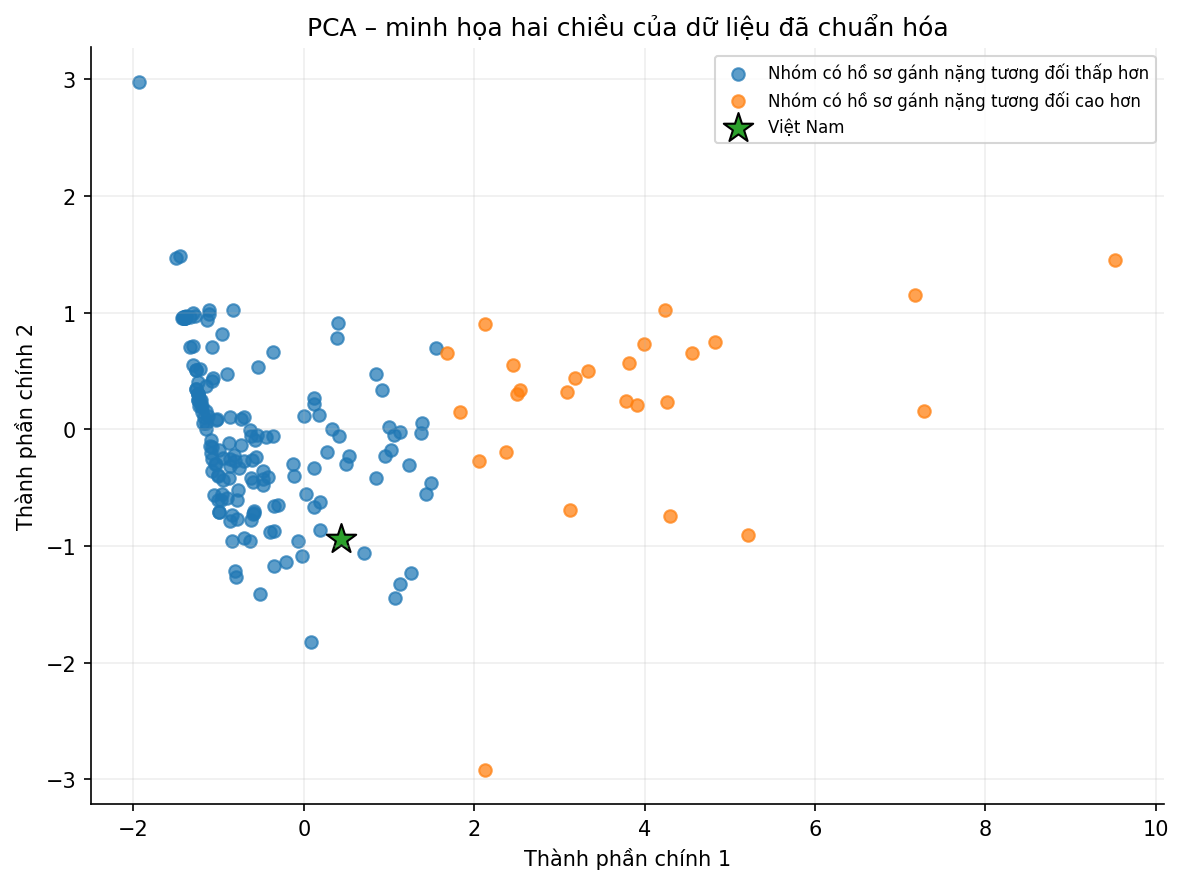

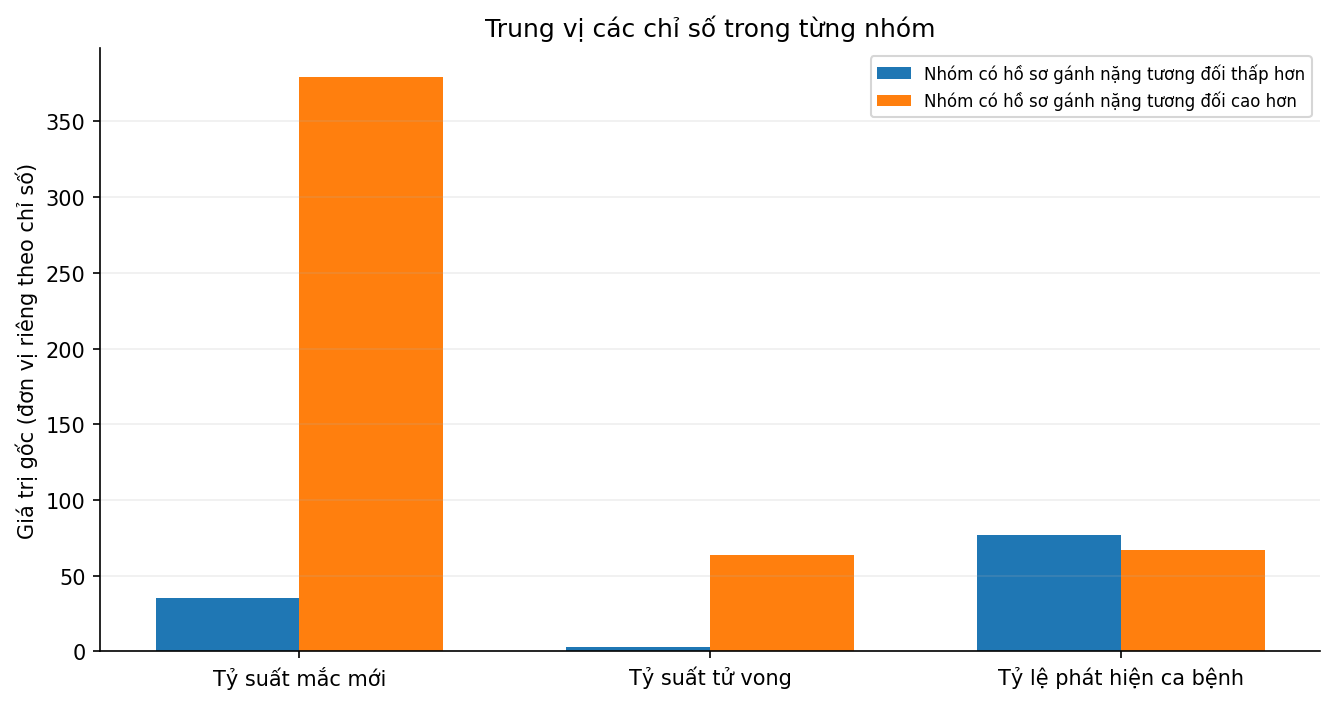

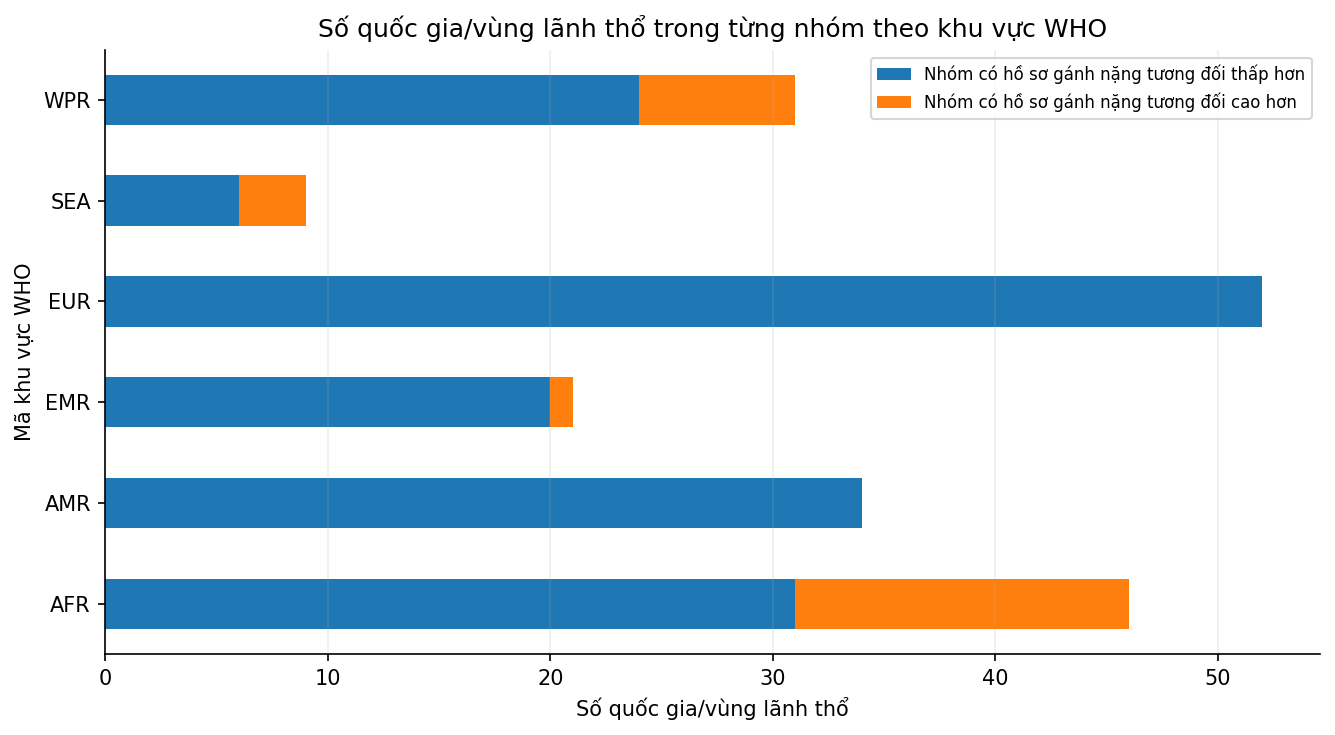

In [4]:
import json
metrics = json.loads((DATA / "TB_kmeans_model_metrics.json").read_text(encoding="utf-8"))
print(json.dumps(metrics, ensure_ascii=False, indent=2))
clusters = pd.read_csv(DATA / "TB_clusters_2024.csv")
profiles = pd.read_csv(DATA / "TB_kmeans_cluster_profiles.csv")
display(profiles)
display(clusters[clusters.iso3.eq("VNM")])
display(Image(filename=str(ROOT / "reports" / "figures" / "10_kmeans_pca_clusters.png")))
display(Image(filename=str(ROOT / "reports" / "figures" / "11_kmeans_cluster_median_profiles.png")))
display(Image(filename=str(ROOT / "reports" / "figures" / "12_kmeans_who_region_distribution.png")))


## 4. Độ ổn định theo khởi tạo

In [5]:
stability = pd.read_csv(DATA / "TB_kmeans_seed_stability.csv")
display(stability)


,configuration,runs,pairwise_comparisons,mean_pairwise_ari,min_pairwise_ari,max_pairwise_ari
0,"RobustScaler - raw, k=2",10,45,0.984769,0.971443,1.0


## 5. Kiểm tra độ nhạy với c_cdr > 100

In [6]:
sensitivity = pd.read_csv(DATA / "TB_kmeans_sensitivity.csv")
display(sensitivity)


,main_rows,sensitivity_rows,cdr_over_100,silhouette_main,silhouette_sensitivity,ari_on_common_countries,changed_assignments
0,193,190,3,0.663761,0.666644,1.0,0


## 6. Cách diễn giải và giới hạn

- Mô hình dùng 3 biến cấp quốc gia trong năm 2024: tỷ suất mắc mới, tỷ suất tử vong và tỷ lệ phát hiện ca bệnh (c_cdr).
- Mô hình được huấn luyện trên 193 quốc gia/vùng lãnh thổ có đủ dữ liệu.
- RobustScaler giảm ảnh hưởng của độ lệch phân phối khi chuẩn hóa nhưng không làm K-means miễn nhiễm với ngoại lệ.
- K=2 được chọn vì đạt Silhouette cao nhất trong 21 cấu hình đã thử; đồng thời kiểm tra độ ổn định và kích thước nhóm.
- Hai nhãn nhóm chỉ mô tả tương đối trong mẫu, không phải phân loại y tế, xếp hạng quốc gia hay kết luận nhân quả.
- PCA chỉ dùng để trực quan hóa hai chiều; mô hình K-means được huấn luyện trong không gian ba biến đã chuẩn hóa.